# Telco Customer Churn Prediction

## ANN with reusable preprocessing

This notebook starts from raw customer records, fits preprocessing on the training split, trains an ANN, compares it with a decision tree, and evaluates the selected ANN threshold. The test split matches the earlier baseline split that was already examined, so interpret its score as a comparison result rather than a completely untouched estimate.

## 1. Load raw data, clean it, and create the splits

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Start from the original customer data, not the already encoded CSV.
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Convert TotalCharges to numeric; blank entries become missing values.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# The EDA notebook dropped these 11 rows, so keep that choice consistent.
df = df.dropna(subset=["TotalCharges"]).copy()

# Convert the target to 0 = stayed, 1 = churned.
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype("int32")

# Keep tenure as a numeric input. Drop the customer identifier and target.
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
binary_columns = ["SeniorCitizen"]
categorical_columns = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
]

model_input_columns = numeric_columns + binary_columns + categorical_columns

assert len(model_input_columns) == len(set(model_input_columns))
assert set(model_input_columns) == set(X.columns)

print("Feature groups cover all input columns.")

# Split before fitting any scaler or encoder.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_full,
)

print("Rows after cleaning:", len(df))
print("Input features:", X.shape[1])
print("Churn rate:", round(y.mean(), 3))
print("Train / validation / test:", len(X_train), len(X_val), len(X_test))
print("Churn included in inputs:", "Churn" in X.columns)

Feature groups cover all input columns.
Rows after cleaning: 7032
Input features: 19
Churn rate: 0.266
Train / validation / test: 4500 1125 1407
Churn included in inputs: False


## 2. Fit and save reusable preprocessing

The continuous inputs are standardized, `SeniorCitizen` passes through unchanged, and categorical inputs are one-hot encoded. The transformer is fitted on training data only and then reused for validation and test data. Keeping this fitted transformer is necessary to preprocess future raw customer records the same way.

In [12]:
import numpy as np
import joblib
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        ("binary", "passthrough", binary_columns),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32,
            ),
            categorical_columns,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Fit only on training data. Use that fitted transformer for validation and test.
X_train_processed = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_processed = preprocessor.transform(X_val).astype(np.float32)
X_test_processed = preprocessor.transform(X_test).astype(np.float32)

feature_names = preprocessor.get_feature_names_out().tolist()

assert X_train_processed.shape[1] == X_val_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_val_processed).all()
assert np.isfinite(X_test_processed).all()

print("Processed train / validation / test:",
      X_train_processed.shape, X_val_processed.shape, X_test_processed.shape)
print("Processed feature count:", len(feature_names))

# Save the fitted preprocessor and the output feature names.
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(exist_ok=True)

joblib.dump(preprocessor, artifacts_dir / "preprocessor.joblib")
joblib.dump(feature_names, artifacts_dir / "preprocessor_feature_names.joblib")

print("Saved reusable preprocessor to:", artifacts_dir.resolve())

Processed train / validation / test: (4500, 45) (1125, 45) (1407, 45)
Processed feature count: 45
Saved reusable preprocessor to: C:\Project\ann-based-customer-churn-prediction\artifacts


## 3. Train the ANN with the reusable preprocessor

The network is trained on the transformed training data. Validation data is used for early stopping; the test set is still held back.


In [13]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(RANDOM_STATE)

model = keras.Sequential([
    keras.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.15),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(curve="PR", name="pr_auc"),
    ],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_roc_auc",
    mode="max",
    patience=12,
    restore_best_weights=True,
)

history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
)

best_epoch = int(np.argmax(history.history["val_roc_auc"]) + 1)

print(f"Best validation ROC AUC: {max(history.history['val_roc_auc']):.3f}")
print(f"Best epoch: {best_epoch} of {len(history.history['loss'])}")

Epoch 1/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7289 - loss: 0.5125 - pr_auc: 0.4491 - roc_auc: 0.7362 - val_accuracy: 0.8009 - val_loss: 0.4372 - val_pr_auc: 0.6353 - val_roc_auc: 0.8301
Epoch 2/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7920 - loss: 0.4456 - pr_auc: 0.6037 - roc_auc: 0.8193 - val_accuracy: 0.7947 - val_loss: 0.4302 - val_pr_auc: 0.6419 - val_roc_auc: 0.8363
Epoch 3/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8020 - loss: 0.4315 - pr_auc: 0.6392 - roc_auc: 0.8334 - val_accuracy: 0.7911 - val_loss: 0.4283 - val_pr_auc: 0.6400 - val_roc_auc: 0.8367
Epoch 4/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7982 - loss: 0.4317 - pr_auc: 0.6332 - roc_auc: 0.8326 - val_accuracy: 0.7929 - val_loss: 0.4285 - val_pr_auc: 0.6382 - val_roc_auc: 0.8355
Epoch 5/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8007 - loss: 0.4235 - pr_auc: 0.6340 - roc_auc: 0.8401 - val_accuracy: 0.7956 - val_loss: 0.4284 - val_pr

## 4. Compare the ANN with a Decision Tree

Both models use the same processed training and validation rows. This table compares their default 0.50 decision threshold; it is a validation comparison, not a test-set comparison. The tree depth and leaf size limit its growth.

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

tree_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    random_state=RANDOM_STATE,
)
tree_model.fit(X_train_processed, y_train)

ann_val_prob = model.predict(X_val_processed, verbose=0).ravel()
tree_val_prob = tree_model.predict_proba(X_val_processed)[:, 1]

ann_val_pred = (ann_val_prob >= 0.50).astype("int32")
tree_val_pred = (tree_val_prob >= 0.50).astype("int32")

comparison = pd.DataFrame([
    {
        "Model": "ANN",
        "Accuracy": accuracy_score(y_val, ann_val_pred),
        "Churn precision": precision_score(y_val, ann_val_pred, zero_division=0),
        "Churn recall": recall_score(y_val, ann_val_pred, zero_division=0),
        "Churn F1": f1_score(y_val, ann_val_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_val, ann_val_prob),
        "PR AUC": average_precision_score(y_val, ann_val_prob),
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_val, tree_val_pred),
        "Churn precision": precision_score(y_val, tree_val_pred, zero_division=0),
        "Churn recall": recall_score(y_val, tree_val_pred, zero_division=0),
        "Churn F1": f1_score(y_val, tree_val_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_val, tree_val_prob),
        "PR AUC": average_precision_score(y_val, tree_val_prob),
    },
]).set_index("Model")

comparison.round(3)

,Accuracy,Churn precision,Churn recall,Churn F1,ROC AUC,PR AUC
Model,,,,,,
ANN,0.791,0.663,0.435,0.525,0.837,0.643
Decision Tree,0.777,0.587,0.542,0.563,0.811,0.589


## 5. Select the ANN threshold on validation data

Because overall accuracy is the current objective, choose the ANN threshold that gives the best validation accuracy. This threshold is selected without using test labels. The comparison above remains a default-threshold comparison at 0.50.

In [15]:
from sklearn.metrics import accuracy_score, classification_report

ann_val_prob = model.predict(X_val_processed, verbose=0).ravel()

threshold_candidates = np.arange(0.10, 0.901, 0.005)
validation_accuracies = [
    accuracy_score(y_val, ann_val_prob >= candidate)
    for candidate in threshold_candidates
]

best_index = int(np.argmax(validation_accuracies))
threshold = float(threshold_candidates[best_index])
ann_val_pred = (ann_val_prob >= threshold).astype("int32")

print(f"Selected ANN threshold: {threshold:.3f}")
print(f"Validation accuracy: {accuracy_score(y_val, ann_val_pred):.3f}")
print(classification_report(
    y_val,
    ann_val_pred,
    labels=[0, 1],
    target_names=["No churn", "Churn"],
    zero_division=0,
))

Selected ANN threshold: 0.470
Validation accuracy: 0.797
              precision    recall  f1-score   support

    No churn       0.83      0.91      0.87       826
       Churn       0.66      0.48      0.56       299

    accuracy                           0.80      1125
   macro avg       0.75      0.70      0.71      1125
weighted avg       0.79      0.80      0.79      1125



## 6. Evaluate the ANN on the holdout split

Apply the selected threshold once to the test probabilities and review the classification report and confusion matrix. This split was also examined during the earlier baseline work, so treat the result as a comparison score and do not tune the model against it.

Selected threshold: 0.470
Test accuracy:      0.795
Test ROC AUC:       0.836
Test PR AUC:        0.622

              precision    recall  f1-score   support

    No churn       0.83      0.90      0.87      1033
       Churn       0.65      0.51      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.72      1407
weighted avg       0.78      0.79      0.79      1407



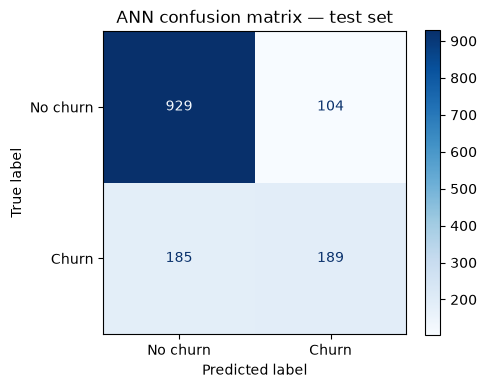

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

test_prob = model.predict(X_test_processed, verbose=0).ravel()
test_pred = (test_prob >= threshold).astype("int32")

print(f"Selected threshold: {threshold:.3f}")
print(f"Test accuracy:      {accuracy_score(y_test, test_pred):.3f}")
print(f"Test ROC AUC:       {roc_auc_score(y_test, test_prob):.3f}")
print(f"Test PR AUC:        {average_precision_score(y_test, test_prob):.3f}")
print()
print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1],
    target_names=["No churn", "Churn"],
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    labels=[0, 1],
    display_labels=["No churn", "Churn"],
    values_format="d",
    cmap="Blues",
    ax=ax,
)
ax.set_title("ANN confusion matrix — test set")
plt.tight_layout()
plt.show()

## 7. Save the production artifacts

Save the trained ANN together with the fitted preprocessor, generated feature names, and validation-selected threshold. The app will need all of these to turn raw customer inputs into predictions.


In [17]:
from pathlib import Path
import json
import joblib

production_dir = Path("artifacts") / "production_pipeline"
production_dir.mkdir(parents=True, exist_ok=True)

model.save(production_dir / "churn_ann.keras")
joblib.dump(preprocessor, production_dir / "preprocessor.joblib")
joblib.dump(feature_names, production_dir / "feature_names.joblib")

metadata = {
    "threshold": float(threshold),
    "threshold_selection": "maximum validation accuracy",
    "target_labels": {"0": "No churn", "1": "Churn"},
    "raw_input_columns": X.columns.tolist(),
}

(production_dir / "metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Saved production artifacts to:", production_dir.resolve())

Saved production artifacts to: C:\Project\ann-based-customer-churn-prediction\artifacts\production_pipeline


In [20]:
from src.predict import predict_customer

sample_customer = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 12,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "Yes",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 70.35,
    "TotalCharges": 844.20,
}

predict_customer(sample_customer)

{'churn_probability': 0.502, 'prediction': 'Churn', 'threshold': 0.47}